# Projet de MACHINE LEARNING I – Classification de la qualité du vin

Le but est de prédire si un vin est bon ou pas à partir de ses caractéristiques physico-chimiques tel que l'acidité, le sucre, l'alcool, pH etc
On utilise le dataset Wine Quality de l'UCI, qui contient des vins rouges et des vins blancs portugais (Vinho Verde).
Chaque vin a une note entre 0 et 10 donnée par des experts. Comme demandé dans le sujet, on transforme le problème en classification binaire :
un vin est considéré comme **bon si sa note est ≥ 7**.

Étapes du notebook :
1. Chargement et description des données
2. Prétraitement (valeurs manquantes, doublons, valeurs aberrantes, encodage)
3. Création de la variable cible et équilibre des classes
4. Visualisations et corrélations
5. Séparation train / test et normalisation
6. Sélection de variables (wrapper)
7. Modélisation (régression logistique, k-NN, arbre de décision, Naive Bayes, SVM)
8. Évaluation des modèles en validation croisée (biais / variance)
9. Optimisation des hyperparamètres et évaluation finale sur le test
10. Conclusion

> ##  Comprendre le sujet en 2 minutes
>
> **La question :** peut-on deviner si un vin est **bon** uniquement à partir de **mesures de laboratoire**, sans le goûter ?
>
> **Pourquoi c'est du machine learning :** personne ne connaît la « formule » d'un bon vin. On donne donc à un algorithme des milliers d'exemples (des vins avec leurs mesures **et** la note des dégustateurs), et il cherche tout seul des règles du type « plus d'alcool et moins d'acidité volatile → souvent un bon vin ». C'est de l'**apprentissage supervisé** : on apprend à partir d'exemples dont on connaît la réponse.
>
> **Classification binaire :** au lieu de prédire la note exacte (3, 4, …, 9), on simplifie en une question **oui / non** : *la note est-elle ≥ 7 ?*
>
> **Le vocabulaire qui revient partout :**
> | Mot | Sens |
> |---|---|
> | **X** (variables, *features*) | les mesures qui servent à prédire (alcool, pH…) |
> | **y** (cible, *target*) | la réponse à prédire (bon = 1, pas bon = 0) |
> | **train** | les vins avec lesquels le modèle **apprend** (les « exercices corrigés ») |
> | **test** | les vins gardés de côté pour **l'examen final** (jamais vus pendant l'apprentissage) |
> | **modèle** | l'algorithme qui apprend les règles (régression logistique, SVM…) |
>
> **Le fil rouge :** explorer les données → les nettoyer → comprendre quelles variables comptent → entraîner 5 modèles → les comparer honnêtement → régler leurs paramètres → choisir le meilleur.
>
> **Données :** le code lit les fichiers `data/winequality-red.csv` et `data/winequality-white.csv` (à la racine du dépôt). Dans Colab, crée un dossier `data/` et dépose-y les deux fichiers.

In [ ]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Chargement des données

Les données sont séparées en deux fichiers (rouge et blanc) avec `;` comme séparateur.
On a choisi de les mettre ensemble pour avoir plus de données, en ajoutant une colonne `type` pour garder l'information rouge/blanc.

In [ ]:
# --- Lecture des deux fichiers CSV ---
# sep=";" : dans ces fichiers, les colonnes sont séparées par des points-virgules (et pas des virgules)
red = pd.read_csv("data/winequality-red.csv", sep=";")      # 1 599 vins rouges
white = pd.read_csv("data/winequality-white.csv", sep=";")  # 4 898 vins blancs

# On ajoute une colonne "type" pour se souvenir de la couleur de chaque vin
# (sinon, une fois les deux tableaux fusionnés, on ne pourrait plus savoir lequel est rouge ou blanc)
red["type"] = "red"
white["type"] = "white"

# pd.concat colle les deux tableaux l'un sous l'autre
# ignore_index=True : on renumérote les lignes de 0 à 6496 (sinon on aurait deux fois les numéros 0, 1, 2...)
df = pd.concat([red, white], ignore_index=True)

# .shape donne (nombre de lignes, nombre de colonnes)
print("rouges :", red.shape, " blancs :", white.shape, " total :", df.shape)

# .head() affiche les 5 premières lignes pour jeter un œil au tableau
df.head()

rouges : (1599, 13)  blancs : (4898, 13)  total : (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [ ]:
# .describe() calcule les statistiques descriptives de chaque colonne numérique :

df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


On a 6497 vins et 13 colonnes : 11 variables numériques continues, la note `quality` et le `type` (texte, à encoder plus tard).

Ce qu'on remarque avec `describe()` :
- les variables n'ont pas du tout la même échelle (la densité est autour de 1 alors que le `total sulfur dioxide` monte jusqu'à 440), il faut donc normaliser les données pour les modèles qui utilisent des distances comme le k-NN ou le SVM .
- pour certaines variables comme `residual sugar`, `chlorides` ou `free sulfur dioxide`, le max est très loin du 3e quartile, donc il y a sûrement des valeurs aberrantes ;
- les notes vont seulement de 3 à 9.

## 2. Prétraitement des données

### Prétraitement : choix effectués
Avant toute modélisation, nous avons nettoyé les données, car un modèle ne peut apprendre correctement que sur des données fiables (« data cleaning » vu en cours : filtrage des données, traitement des valeurs manquantes et des valeurs anormales).

Nous avons d'abord vérifié l'absence de valeurs manquantes, que la plupart des modèles ne supportent pas : il n'y en a aucune, donc aucune imputation n'a été nécessaire.

Nous avons ensuite supprimé les doublons, avant la séparation train/test : une même ligne présente dans les deux jeux aurait permis au modèle d'être évalué sur un vin déjà vu et aurait gonflé artificiellement son score.

Pour les valeurs aberrantes, repérées avec les boxplots (règle de Tukey : 1,5 × l'écart interquartile), nous n'avons fait aucune suppression : un vin très sucré ou très sulfité est un cas réel et pas forcément une erreur, et le retirer ferait perdre de l'information utile. Nous avons vérifié que les valeurs extrêmes restent plausibles et nous avons conservé toutes les lignes ; leur influence est limitée par la standardisation.

Enfin, nous avons encodé la variable `type` en 0 / 1 : les modèles ne manipulent que des nombres (« les données de catégorie sont codées dans une représentation numérique », cours), et comme elle n'a que deux modalités sans ordre entre elles, un codage binaire suffit et n'introduit aucune hiérarchie artificielle. Toutes les transformations qui dépendent des données (standardisation, sélection, réglages) sont ajustées sur le jeu d'entraînement uniquement, pour que le jeu de test reste une évaluation honnête.

### Valeurs manquantes

In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Il n'y a aucune valeur manquante, donc pas besoin de faire d'imputation.

### Doublons

In [ ]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 1177


In [ ]:
print("Nombre de doublons dans red :", red.duplicated().sum())


Nombre de doublons dans red : 240


In [ ]:
print("Nombre de doublons dans white :", white.duplicated().sum())


Nombre de doublons dans white : 937


Le jeu de données contient 1177 doublons, soit environ 18 % des 6497 lignes.

 Ce chiffre correspond exactement à la somme des doublons déjà présents dans chaque fichier d'origine (240 dans `red` et 937 dans `white`, soit 240 + 937 = 1177).

  La concaténation des deux dataframes n'a donc créé aucun doublon supplémentaire : tous préexistaient dans les fichiers sources, et aucun vin rouge n'a de copie parmi les vins blancs.
  
   Nous supprimons ces lignes, car une même observation présente à la fois dans le train et dans le test fausserait l'évaluation des modèles, qui seraient testés sur des données qu'ils ont déjà vues.
   
   Cette suppression est faite avant la séparation train/test.

In [ ]:
df = df.drop_duplicates()
print("Taille après suppression :", df.shape)

Taille après suppression : (5320, 13)


### Valeurs aberrantes

Le sujet demande de détecter les valeurs aberrantes et d'utiliser des boxplots. On utilise donc la règle des boxplots (règle de Tukey) : une valeur est aberrante si elle est en dehors de [Q1 - 1.5×IQR ; Q3 + 1.5×IQR], où IQR = Q3 - Q1 est l'écart interquartile. Ce sont exactement les limites des « moustaches » d'un boxplot.

In [ ]:
# Liste des 11 variables physico-chimiques : toutes les colonnes SAUF la note et le type
variables = df.columns.drop(["quality", "type"])

# Pour chaque variable, on compte les valeurs aberrantes avec la règle de l'IQR
for col in variables:
    Q1 = df[col].quantile(0.25)   # 1er quartile : 25 % des vins ont une valeur plus petite
    Q3 = df[col].quantile(0.75)   # 3e quartile : 75 % des vins ont une valeur plus petite
    IQR = Q3 - Q1                 # écart interquartile = largeur de la "boîte" du boxplot
    # Une valeur est aberrante si elle est trop loin de la boîte :
    # sous Q1 - 1.5*IQR OU (le symbole |) au-dessus de Q3 + 1.5*IQR

    # permet de compter les oultiers de chaque colonne
    nb = ((df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)).sum()


    print(f"{col:22s} : {nb} valeurs aberrantes ({nb / len(df) * 100:.1f} %)")

fixed acidity          : 304 valeurs aberrantes (5.7 %)
volatile acidity       : 279 valeurs aberrantes (5.2 %)
citric acid            : 143 valeurs aberrantes (2.7 %)
residual sugar         : 141 valeurs aberrantes (2.7 %)
chlorides              : 237 valeurs aberrantes (4.5 %)
free sulfur dioxide    : 44 valeurs aberrantes (0.8 %)
total sulfur dioxide   : 10 valeurs aberrantes (0.2 %)
density                : 3 valeurs aberrantes (0.1 %)
pH                     : 49 valeurs aberrantes (0.9 %)
sulphates              : 163 valeurs aberrantes (3.1 %)
alcohol                : 1 valeurs aberrantes (0.0 %)


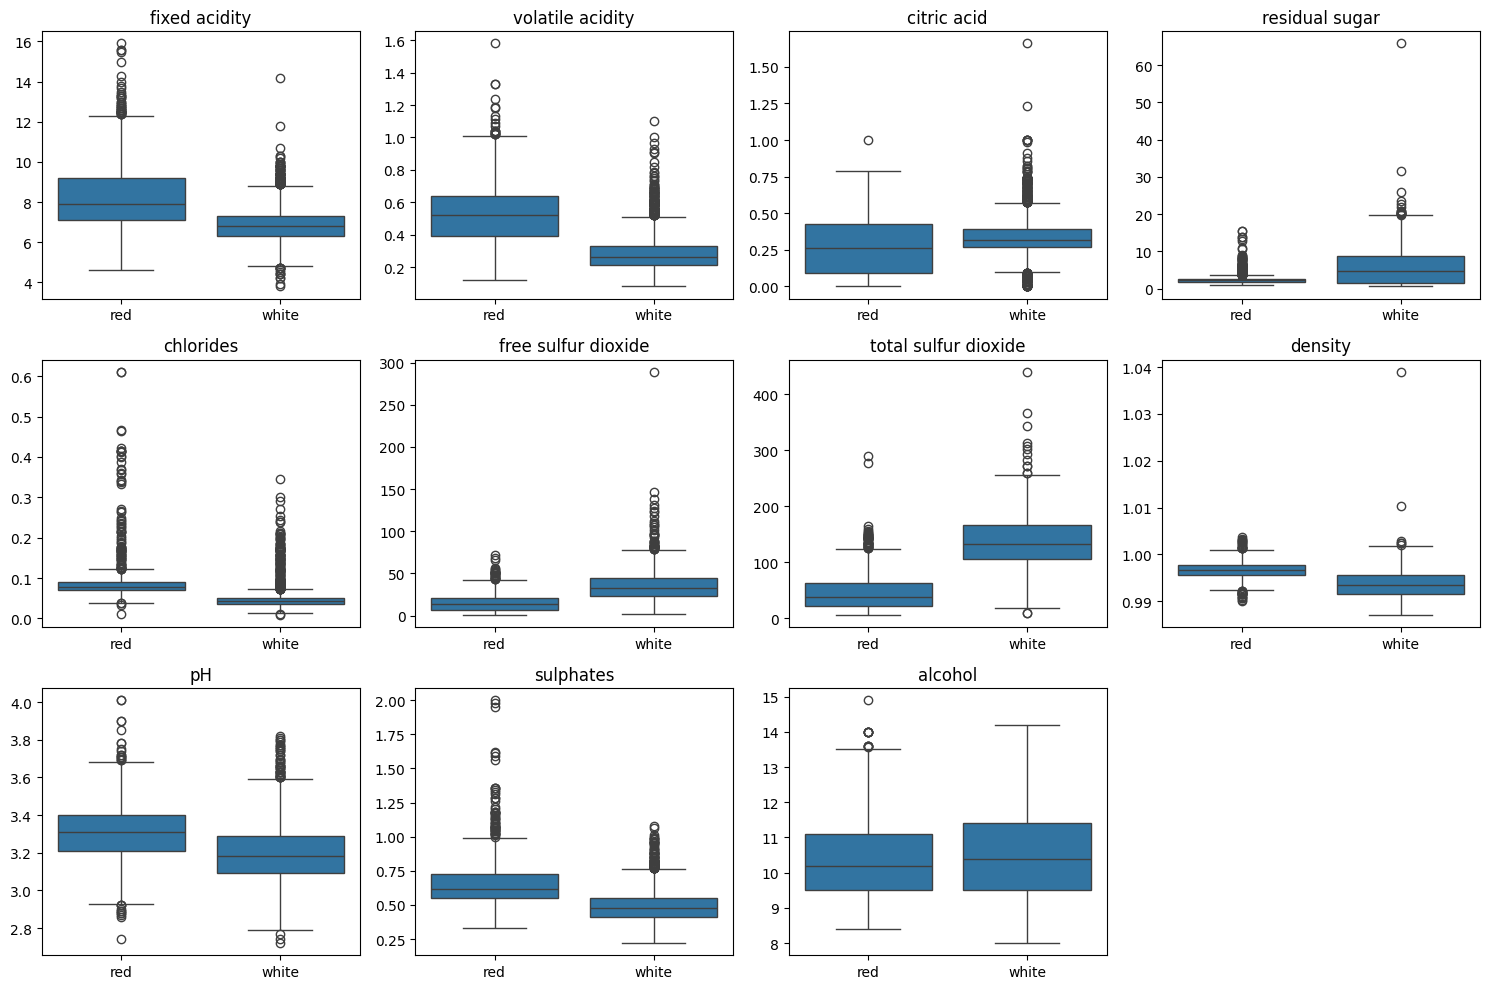

In [ ]:
# Un boxplot par variable, en séparant rouges et blancs, pour voir D'OÙ viennent les valeurs aberrantes


plt.figure(figsize=(15, 10))                 # taille de la figure en pouces (largeur, hauteur)

for i, col in enumerate(variables):          # enumerate donne le numéro i (0, 1, 2...) ET le nom de la variable
    plt.subplot(3, 4, i + 1)                 # grille de 3 lignes x 4 colonnes ; i+1 = position (commence à 1)
    sns.boxplot(data=df, x="type", y=col)    # une boîte pour les rouges, une pour les blancs
    plt.title(col)
    plt.xlabel("")                           # on enlève les étiquettes d'axes pour alléger
    plt.ylabel("")
plt.tight_layout()                           # évite que les titres se chevauchent
plt.show()

In [ ]:
def bornes(s, k=1.5):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    i = q3 - q1
    return q1 - k*i, q3 + k*i

d = df.copy()
# marche que `type` soit encore en texte ou déjà encodé en 0/1
d["couleur"] = d["type"].map({0: "blanc", 1: "rouge", "white": "blanc", "red": "rouge"})
palette = {"blanc": "#d9b44a", "rouge": "#a4262c"}
ordre = ["blanc", "rouge"]

# out_<variable> = True si la valeur est aberrante PAR RAPPORT À SON TYPE
for col in variables:
    d["out_" + col] = d.groupby("couleur")[col].transform(
        lambda s: (s < bornes(s)[0]) | (s > bornes(s)[1]))

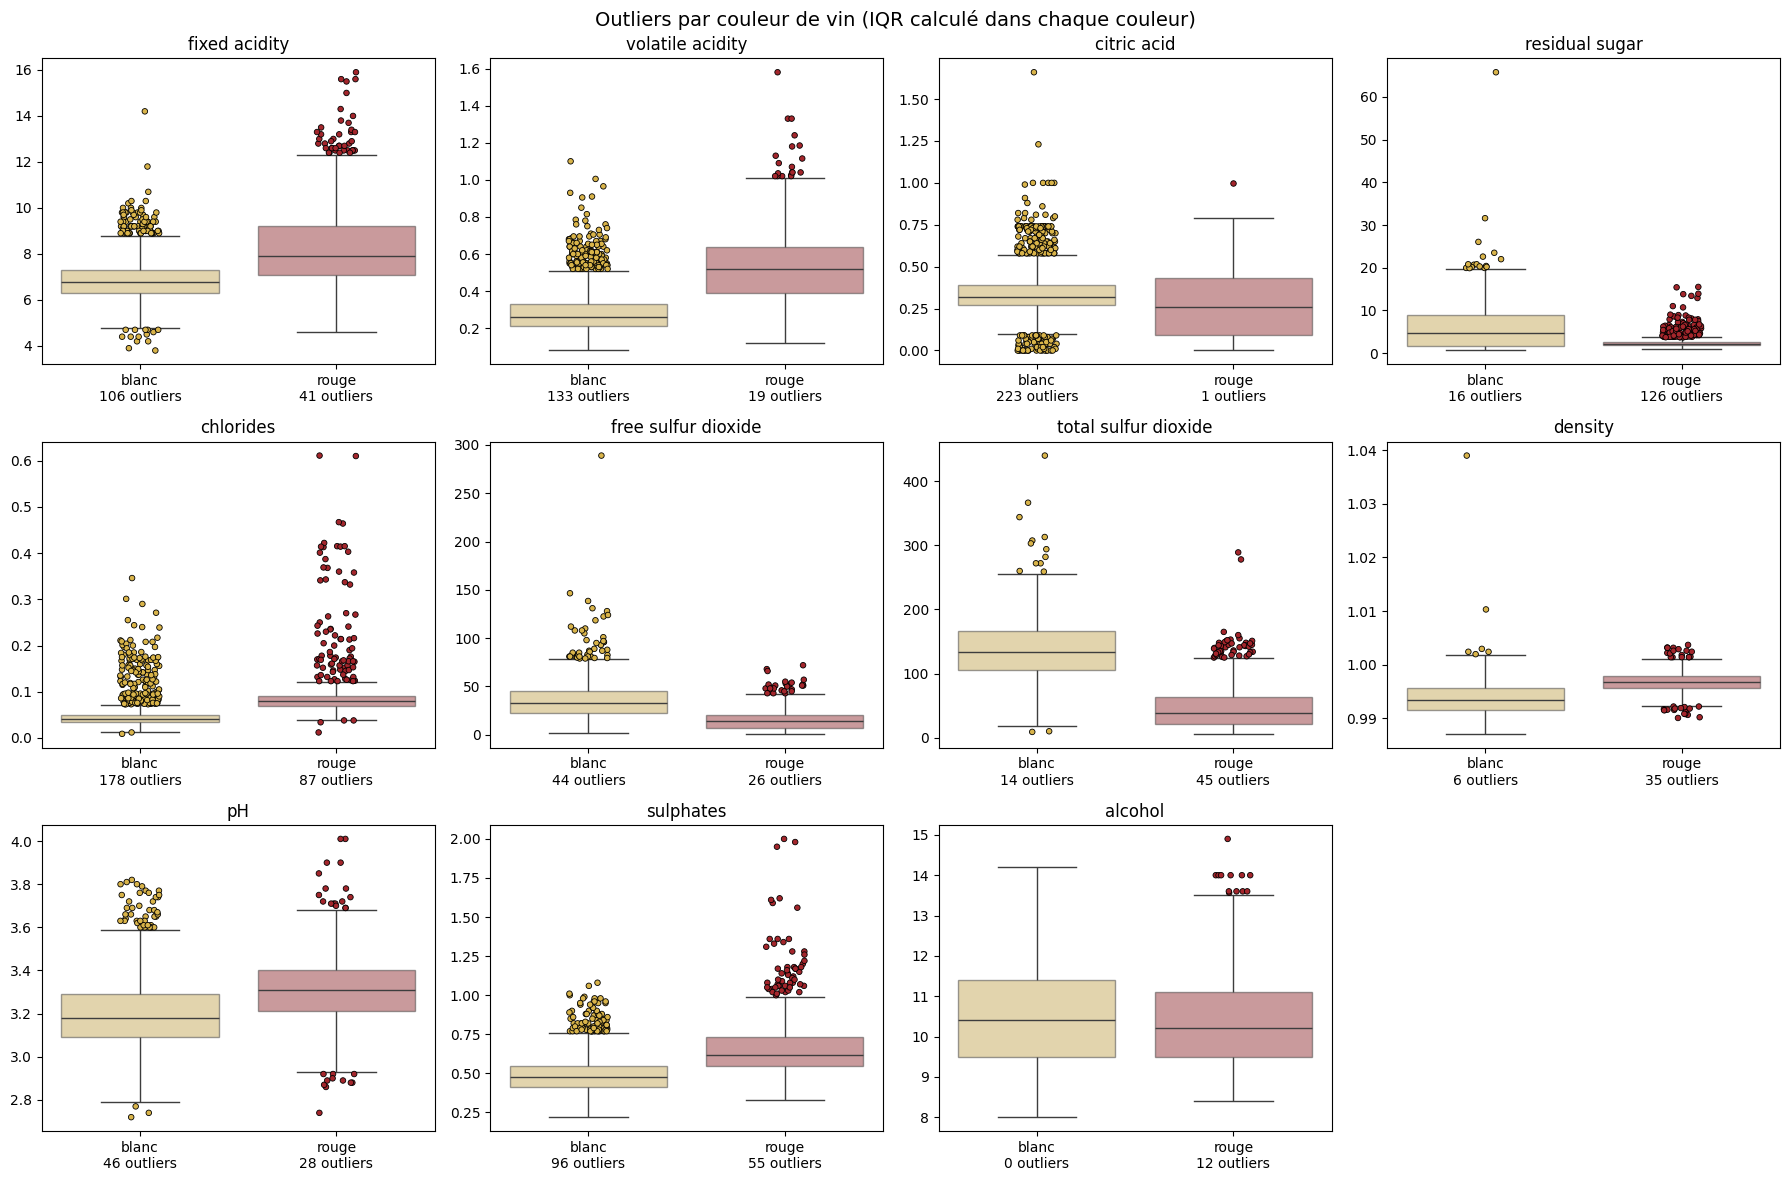

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, col in zip(axes.ravel(), variables):
    sns.boxplot(data=d, x="couleur", y=col, hue="couleur", order=ordre,
                palette=palette, showfliers=False, boxprops={"alpha": .5},
                legend=False, ax=ax)
    o = d[d["out_" + col]]
    sns.stripplot(data=o, x="couleur", y=col, hue="couleur", order=ordre,
                  palette=palette, edgecolor="black", linewidth=.6, size=4,
                  legend=False, ax=ax)
    n = d.groupby("couleur")["out_" + col].sum()
    ax.set_xticks(range(2))
    ax.set_xticklabels([f"{t}\n{n[t]} outliers" for t in ordre])
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Outliers par couleur de vin (IQR calculé dans chaque couleur)", fontsize=14)
plt.tight_layout()
plt.show()

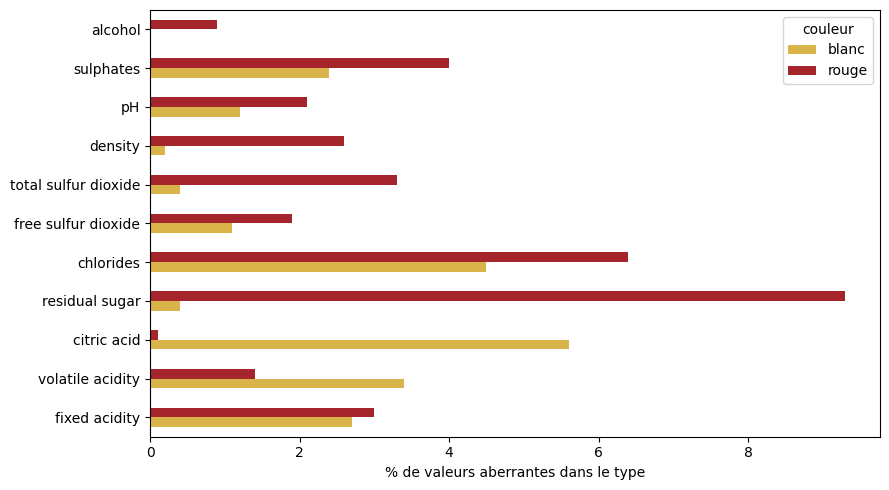

couleur               blanc  rouge
fixed acidity           2.7    3.0
volatile acidity        3.4    1.4
citric acid             5.6    0.1
residual sugar          0.4    9.3
chlorides               4.5    6.4
free sulfur dioxide     1.1    1.9
total sulfur dioxide    0.4    3.3
density                 0.2    2.6
pH                      1.2    2.1
sulphates               2.4    4.0
alcohol                 0.0    0.9


In [ ]:
tab = (d.groupby("couleur")[[ "out_" + c for c in variables]].mean().T * 100)
tab.index = variables
tab[ordre].round(1).plot(kind="barh", figsize=(9, 5),
                         color=[palette[t] for t in ordre])
plt.xlabel("% de valeurs aberrantes dans le type")
plt.tight_layout()
plt.show()
print(tab[ordre].round(1))

Nous avons recalculé l’IQR séparément pour les vins rouges et les vins blancs, car les deux types ont des compositions très différentes (les rouges ont plus d’acidité, de chlorures et de sulphates, les blancs plus de sucre résiduel et de SO₂).

Le nombre total de valeurs aberrantes reste proche (environ 1 370 sur le jeu combiné contre environ 1 340 par type), mais sa répartition change.

Pour fixed acidity et volatile acidity, le nombre d’outliers est divisé par deux environ (304 → 147 et 279 → 152) : une partie des valeurs signalées sur le jeu combiné venait seulement de la différence entre rouges et blancs. À l’inverse, total sulfur dioxide (10 → 59), density (3 → 41), citric acid (143 → 224) et alcohol (1 → 12) comptent plus d’outliers par type, car le mélange les masquait.

 Dans chaque type, les valeurs aberrantes représentent le plus souvent 1 à 6 % des vins et forment des queues continues de distribution, par exemple chlorides (4,5 % des blancs, 6,4 % des rouges) ou citric acid chez les blancs (5,6 %), ce qui correspond à des vins réellement atypiques et non à des erreurs. Le pourcentage élevé de residual sugar chez les rouges (environ 9 %) s’explique par une distribution très resserrée autour de 2 g/L, où la règle de l’IQR devient très stricte : les valeurs signalées (4 à 15 g/L) restent plausibles pour un vin. Seules quelques valeurs sont isolées, comme un residual sugar de 66 g/L, un free sulfur dioxide d’environ 289 et une density de 1,039 chez les blancs, ou des chlorides de 0,61 chez les rouges. Elles restent cohérentes avec les autres mesures du même vin.

**Nous avons donc conservé toutes les valeurs, en limitant leur influence par la normalisation**.

### Encodage de la variable `type`

C'est la seule variable catégorielle et elle n'a que deux valeurs, donc on la remplace simplement par 0 (blanc) / 1 (rouge).

In [ ]:
# Les modèles ne comprennent que des nombres : on remplace le texte par 0 / 1

df["type"] = df["type"].map({"white": 0, "red": 1})

# On vérifie le résultat
df["type"].value_counts()

,count
type,
0,3961
1,1359


## 3. Variable cible et équilibre des classes

Le sujet demande une classification binaire : nous transformons la note `quality` (de 3 à 9) en une cible `bon`, égale à 1 si la note est ≥ 7 et à 0 sinon.



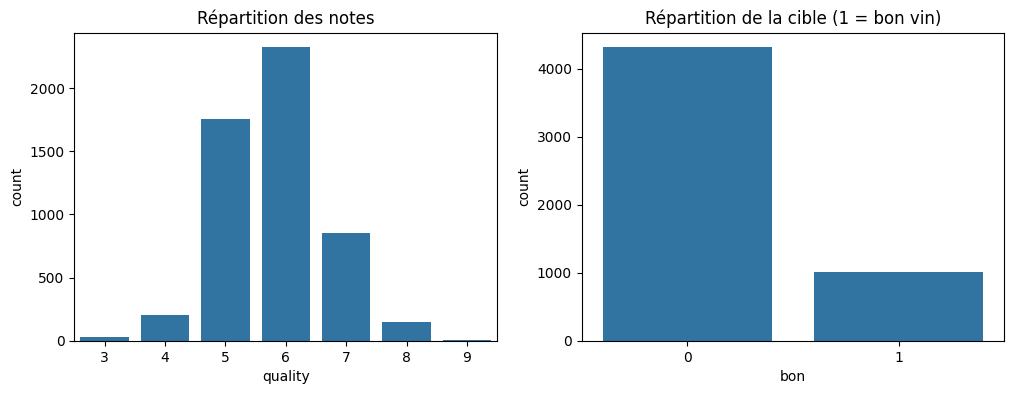

bon
0    0.810338
1    0.189662
Name: proportion, dtype: float64


In [ ]:
# --- Création de la cible binaire ---
# (df["quality"] >= 7) donne True/False pour chaque vin ;
df["bon"] = (df["quality"] >= 7).astype(int)

# Deux graphiques côte à côte
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="quality", ax=ax[0])   # nombre de vins pour chaque note
ax[0].set_title("Répartition des notes")
sns.countplot(data=df, x="bon", ax=ax[1])       # nombre de vins "pas bons" (0) et "bons" (1)
ax[1].set_title("Répartition de la cible (1 = bon vin)")
plt.show()

# normalize=True : donne des proportions (0.81 = 81 %) au lieu de nombres bruts
print(df["bon"].value_counts(normalize=True))

Le seuil de 7 sépare les vins jugés réellement bons des vins mauvais. Il a une conséquence importante : seuls environ 19 % des vins sont « bons » (contre 81 % de « pas bons »), donc les classes sont déséquilibrées.

Ce déséquilibre rend l'accuracy trompeuse. Un modèle qui répondrait toujours « pas bon » aurait environ 81 % de bonnes réponses sans avoir rien appris, et il ne repérerait aucun bon vin, alors que c'est justement la classe qui nous intéresse. Nous avons donc fait trois choix :

- **Découpage train/test stratifié** (`stratify=y`) : le train et le test gardent la même proportion de bons vins (environ 19 %), ce qui rend l'évaluation comparable d'un modèle à l'autre.
- **`class_weight="balanced"`** quand le modèle le permet : nous pénalisons davantage une erreur sur un bon vin (rare) qu'une erreur sur un mauvais vin, pour que le modèle ne se contente pas de prédire la classe majoritaire.
- **Métriques adaptées** : nous jugeons les modèles sur le F1-score de la classe « bon » (qui combine précision et rappel) et sur l'AUC (qui ne dépend pas du seuil de décision), l'accuracy ne servant que de complément.

*Remarque :* `class_weight` revient à donner un poids plus important aux exemples de la classe rare pendant l'apprentissage (même idée que la pondération des observations d'AdaBoost vue en cours). Une alternative vue en cours serait de garder un apprentissage classique et de choisir un autre seuil de décision que 0,5 à l'aide de la courbe ROC.

## 4. Visualisations et corrélations

### Histogrammes

> ### Comprendre : les visualisations
> | Graphique | Ce qu'il montre | Ce qu'on cherche |
> |---|---|---|
> | **Histogramme** | la répartition des valeurs d'une variable | une forme en « cloche » (loi normale) ou une forme étirée (asymétrique) |
> | **Boxplot par classe** | une boîte pour les bons vins, une pour les autres | des boîtes **à des hauteurs différentes** = variable utile pour distinguer |
> | **Matrice de corrélation** | le lien (de -1 à +1) entre chaque paire de variables | les variables liées à la cible, et les **doublons** (deux variables très liées entre elles) |
>
> **La corrélation en une phrase :** +1 = les deux montent ensemble, -1 = l'une monte quand l'autre descend, 0 = aucun lien (linéaire).

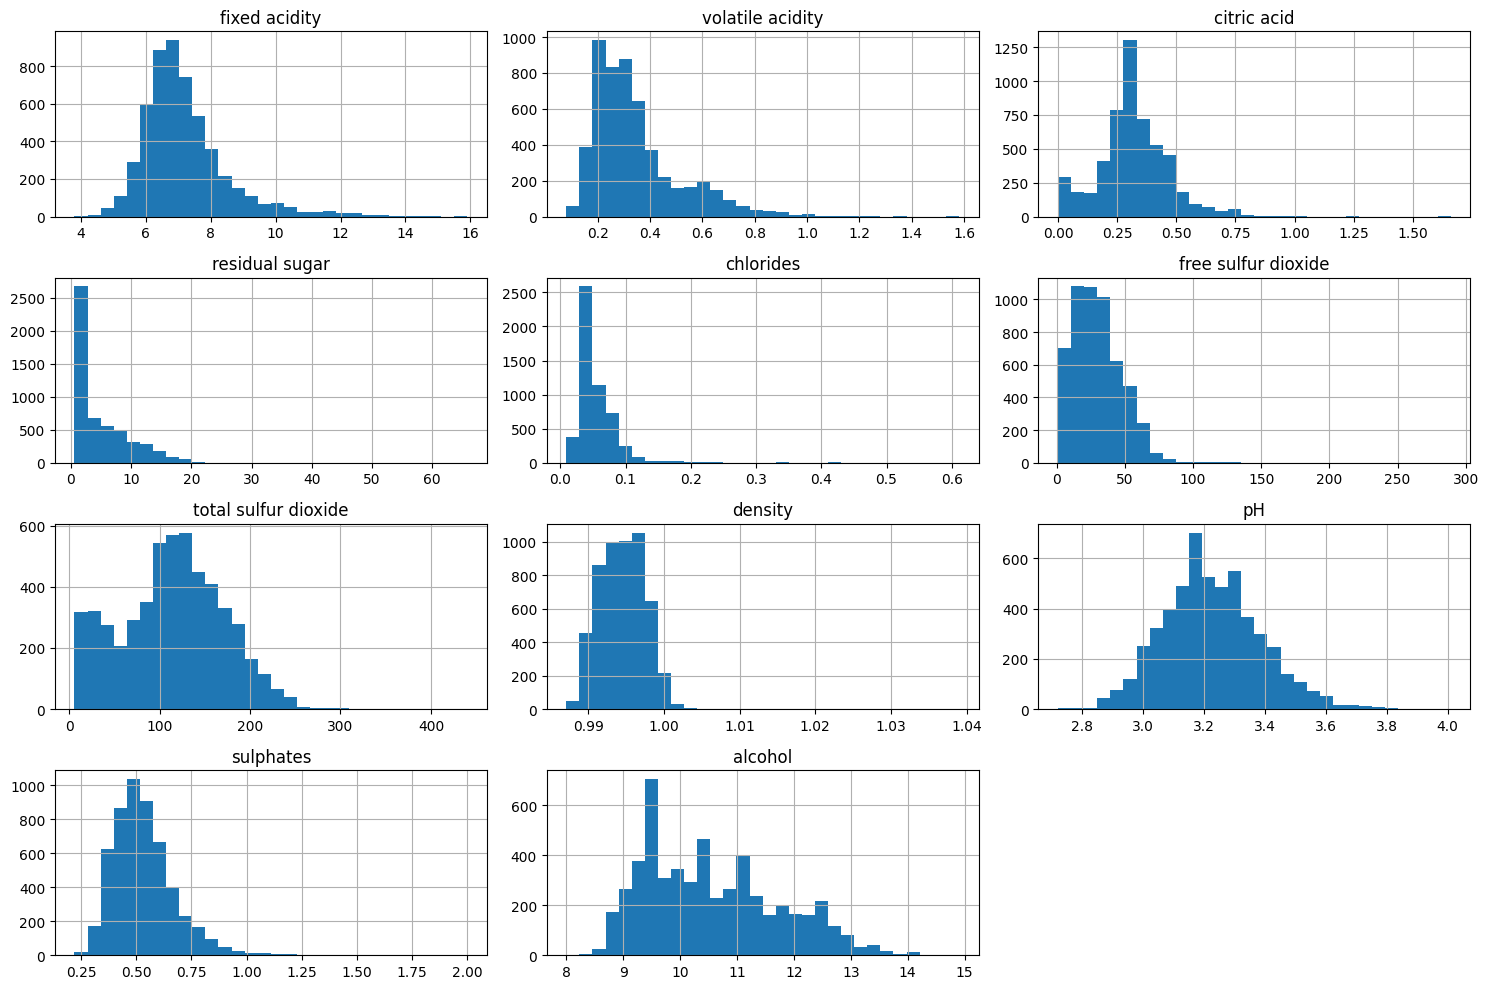

In [ ]:
# Un histogramme par variable : on voit la FORME de la distribution
# (symétrique en cloche ? étirée vers la droite ? plusieurs bosses ?)
# bins=30 : chaque histogramme est découpé en 30 barres
df[variables].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

Beaucoup de variables sont asymétriques avec une longue queue à droite (`chlorides`, `residual sugar`, `sulphates`...).
Elles ne suivent donc pas une loi normale, ce qui risque de poser problème pour Naive Bayes gaussien qui suppose justement des variables gaussiennes.

### Matrice de corrélation

On calcule le coefficient de corrélation de Pearson (vu en cours) entre toutes les variables, puis entre chaque variable et la cible.

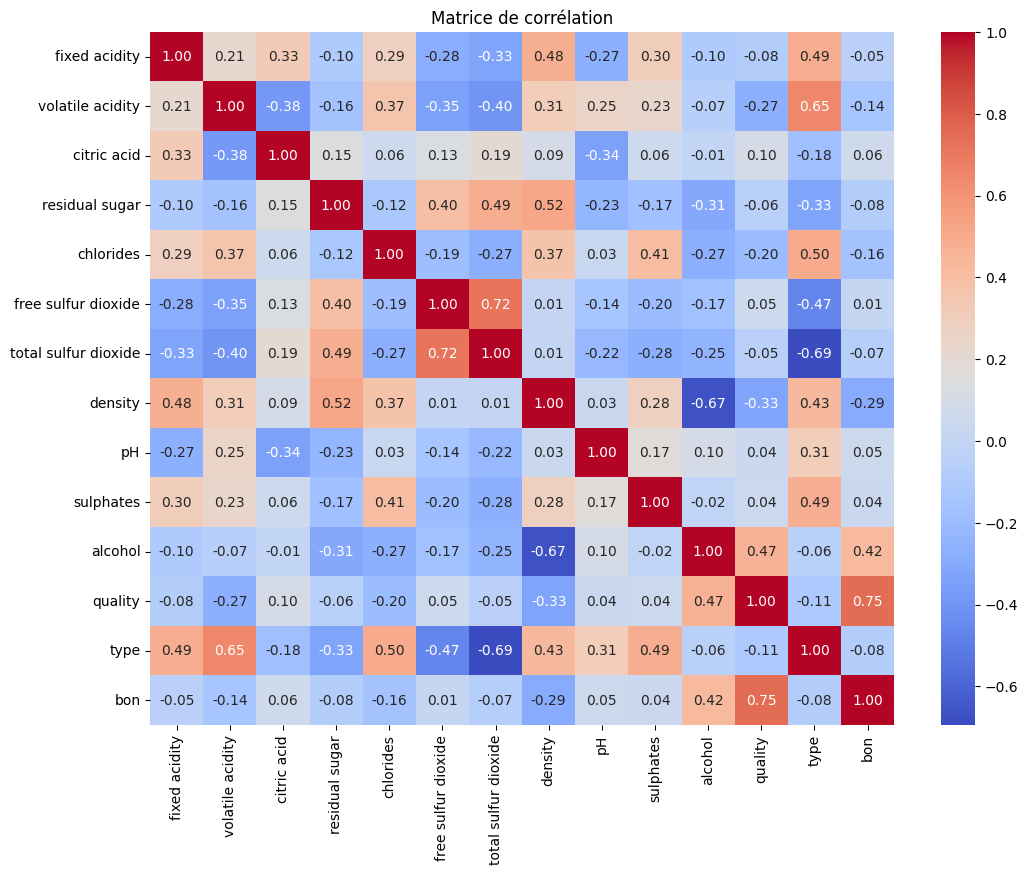

In [ ]:
# Matrice de corrélation

plt.figure(figsize=(12, 9))

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

In [ ]:
# On ne garde que la colonne "bon" de la matrice : la corrélation de chaque variable avec la cible
# .drop(["bon", "quality"]) : on enlève "bon" (corrélation avec elle-même = 1)
#   et "quality" (la cible est fabriquée à partir de la note, ce serait de la triche)
# .sort_values() : du plus négatif au plus positif
df.corr()["bon"].drop(["bon", "quality"]).sort_values()

,bon
density,-0.294971
chlorides,-0.161027
volatile acidity,-0.144361
residual sugar,-0.084868
type,-0.081083
total sulfur dioxide,-0.067307
fixed acidity,-0.049841
free sulfur dioxide,0.011325
sulphates,0.036771
pH,0.048330


Corrélations avec la cible :
- `alcohol` est la variable la plus corrélée avec le fait d'être un bon vin (0.42) ;
- `density`, `chlorides` et `volatile acidity` sont corrélées négativement ;
- les autres variables sont très peu corrélées (mais ça ne veut pas forcément dire qu'elles sont inutiles, la corrélation ne mesure que les relations linéaires).

Corrélations entre les variables :
- `free sulfur dioxide` et `total sulfur dioxide` (0.72), ce qui est logique puisque le SO2 libre fait partie du SO2 total ;
- `density` et `alcohol` (-0.67) et `density` et `residual sugar` (0.52) : la densité dépend en fait de l'alcool et du sucre ;
- `type` est assez corrélé aux sulfites, à l'acidité volatile et aux chlorides (ce qu'on avait vu sur les boxplots).

Ces corrélations entre variables (multicolinéarité) peuvent gêner la régression logistique et Naive Bayes, qui suppose que les variables sont indépendantes.

### Boxplots selon la classe

On trace maintenant les boxplots « bon / pas bon » pour les **4 variables les plus corrélées à la cible** d'après le tableau ci-dessus (en valeur absolue) : `alcohol` (0.42), `density` (-0.29), `chlorides` (-0.16) et `volatile acidity` (-0.14). Après ces 4 variables, les corrélations deviennent très faibles (moins de 0.09 en valeur absolue).

Ce choix est aussi cohérent avec la connaissance du vin : l'alcool donne du corps au vin, l'acidité volatile correspond surtout à l'acide acétique (goût de vinaigre, un défaut classique), les chlorures au sel, et la densité dépend directement de l'alcool et du sucre.

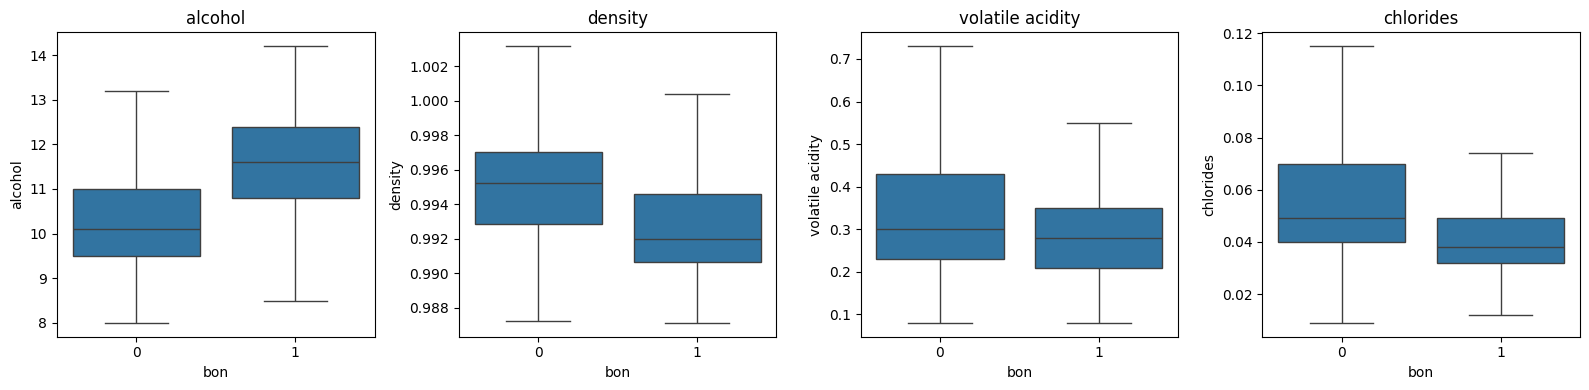

In [ ]:
# Boxplots selon la classe (0 = pas bon, 1 = bon) pour 4 variables qui semblent intéressantes
# Si les deux boîtes sont à des hauteurs différentes, la variable aide à distinguer les bons vins
fig, ax = plt.subplots(1, 4, figsize=(16, 4))   # 4 graphiques côte à côte
for i, col in enumerate(["alcohol", "density", "volatile acidity", "chlorides"]):
    # showfliers=False : on cache les points aberrants pour mieux voir les boîtes
    sns.boxplot(data=df, x="bon", y=col, ax=ax[i], showfliers=False)
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

Les bons vins ont clairement plus d'alcool, et ils sont un peu moins denses, avec moins d'acidité volatile et moins de chlorides.
L'alcool a l'air d'être la variable qui sépare le mieux les deux classes, ce qui confirme la matrice de corrélation.

## 5. Séparation train / test et normalisation

On garde 20 % des données pour le test. On fait la sélection de variables et l'optimisation seulement sur le train,
pour que le test reste vraiment « nouveau » pour le modèle.

> ### Comprendre : train / test et normalisation
> **Train / test, l'analogie de l'examen :** un élève révise avec des exercices corrigés (le **train**), puis passe un examen avec des questions qu'il n'a jamais vues (le **test**). Si on lui donnait les questions de l'examen pendant ses révisions, sa note ne prouverait rien. Ici, 80 % des vins servent à apprendre et 20 % sont gardés pour l'examen final.
>
> **Fuite de données (*data leakage*) :** utiliser, même sans le vouloir, une information du test pendant l'apprentissage. C'est pour ça que toutes les décisions (normalisation, sélection, réglages) sont prises **uniquement sur le train**.
>
> **Normalisation (StandardScaler) :** les variables n'ont pas la même échelle (la densité vaut environ 1, les sulfites jusqu'à 440). Pour les modèles qui calculent des **distances** (k-NN, SVM), une variable à grands nombres écraserait les autres. On transforme donc chaque variable pour qu'elle ait une **moyenne de 0** et un **écart-type de 1** : z = (valeur − moyenne) / écart-type. C'est la standardisation (z-score) vue en cours, recommandée quand les variables ont des unités très différentes, ce qui est notre cas.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["quality", "bon"])
# y = la "réponse" à prédire (0 ou 1)
y = df["bon"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print("train :", X_train.shape, " test :", X_test.shape)
# y_train.mean() = proportion de 1 = proportion de bons vins
print("proportion de bons vins train / test :", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

train : (4256, 12)  test : (1064, 12)
proportion de bons vins train / test : 0.19 / 0.19


## 6. Sélection de variables

On teste les trois familles de méthodes vues en cours :
- **filtre** : le coefficient de corrélation de Pearson entre chaque variable et la cible, calculé sur le train ; il note chaque variable indépendamment du modèle ;
- **wrapper** : `RFE` (Recursive Feature Elimination), qui entraîne une régression logistique et enlève à chaque fois la variable la moins utile ;
- **embedded** : la régularisation **Lasso** (pénalité L1). Pendant l'apprentissage, le Lasso pousse les coefficients des variables peu utiles à exactement 0 : la sélection fait partie de la construction du modèle. Pour une classification, on l'applique à une régression logistique.

> ###  Comprendre : la sélection de variables
> **But :** garder les variables utiles et enlever celles qui n'apportent rien. Un modèle avec moins de variables est plus simple, plus rapide, plus facile à expliquer, et sur-apprend moins.
>
> **Les 3 familles de méthodes vues en cours :**
> | Famille | Principe | Analogie |
> |---|---|---|
> | **Filtre** (corrélation de Pearson) | note chaque variable **seule**, sans modèle | noter chaque joueur sur ses statistiques individuelles |
> | **Wrapper** (RFE) | entraîne un modèle, retire la variable la moins utile, recommence | faire des matchs en retirant un joueur à chaque fois pour voir qui manque le plus |
> | **Embedded** (Lasso / L1) | le modèle met lui-même à 0 le poids des variables inutiles **pendant** l'apprentissage | l'entraîneur laisse sur le banc les joueurs qui ne servent pas |
>
Nous utilisons la méthode RFE (Recursive Feature Elimination), de type wrapper,  : elle entraîne une régression logistique, retire à chaque tour la variable la moins utile, et fournit un classement complet des variables. Contrairement à un filtre, elle évalue les variables ensemble et tient donc compte de leurs corrélations (par exemple densité / alcool).

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# --- Méthode WRAPPER : RFE (Recursive Feature Elimination) ---
rfe = RFE(LogisticRegression(max_iter=1000, class_weight="balanced"),
          n_features_to_select=1).fit(X_train_sc, y_train)

# Tableau : une ligne par variable, triée de la meilleure (rang 1) à la moins utile
selection = pd.DataFrame({"rang RFE": rfe.ranking_}, index=X.columns).sort_values("rang RFE")


selection

,rang RFE
alcohol,1
volatile acidity,2
fixed acidity,3
pH,4
density,5
residual sugar,6
sulphates,7
total sulfur dioxide,8
free sulfur dioxide,9
chlorides,10


La RFE classe `alcohol` en 1re position, ce qui confirme que c'est de loin la variable la plus importante : c'est aussi la plus corrélée à la cible (0.42, étape 4). `volatile acidity` arrive en 2e position, ce qui est cohérent avec sa corrélation négative avec la qualité.

Par contre, le classement des autres variables diffère de celui des corrélations simples :

* `density` est la 2e variable la plus corrélée à la cible (-0.29), mais la RFE la classe seulement 5e. C'est logique : la densité dépend en grande partie de l'alcool et du sucre (corrélation de -0.67 avec l'alcool). Une fois ces variables prises en compte, elle apporte peu d'information en plus. La RFE évalue les variables **ensemble** et écarte donc ces redondances, alors qu'une corrélation les juge une par une ;
* `chlorides` est la 3e variable la plus corrélée à la cible (-0.16), mais elle n'est qu'en 10e position pour la RFE : son effet est largement redondant avec celui des autres variables ;
* `fixed acidity` et `pH` ont une corrélation faible avec la cible, mais la RFE les classe 3e et 4e : elles deviennent utiles **en combinaison** avec les autres variables (l'acidité fixe, le pH et la densité sont liés entre eux), ce qu'une corrélation simple ne peut pas voir ;
* `residual sugar` (6e), `sulphates` (7e) et les deux SO₂ (8e et 9e) occupent le milieu du classement ;
* `type` (11e) et `citric acid` (12e) sont classées en dernier : leur retrait dégrade très peu le modèle.

Ce classement a une limite : la RFE s'appuie sur une régression logistique, donc sur un modèle **linéaire**. Une variable utile seulement de façon non linéaire pourrait être sous-classée.

Pour décider combien de variables garder, on compare le F1 en validation croisée d'une régression logistique avec les k meilleures variables selon le classement RFE :

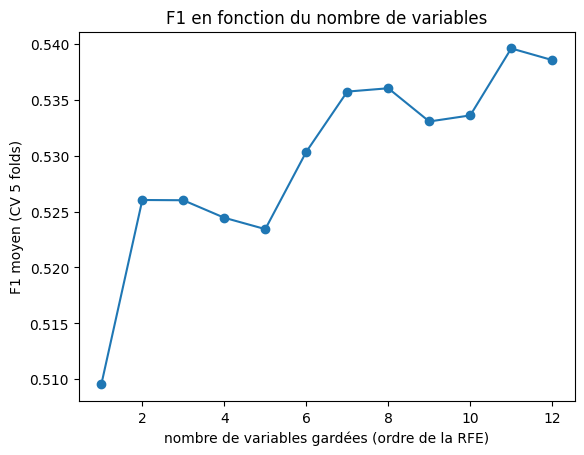

['1: 0.510', '2: 0.526', '3: 0.526', '4: 0.524', '5: 0.523', '6: 0.530', '7: 0.536', '8: 0.536', '9: 0.533', '10: 0.534', '11: 0.540', '12: 0.539']


In [ ]:
from sklearn.model_selection import cross_val_score


ordre = selection.sort_values("rang RFE").index
scores_k = []

for k in range(1, len(ordre) + 1):

    cols = [list(X.columns).index(c) for c in ordre[:k]]
    s = cross_val_score(LogisticRegression(max_iter=1000, class_weight="balanced"),
    X_train_sc[:, cols], y_train, cv=5, scoring="f1")
    scores_k.append(s.mean())

plt.plot(range(1, len(ordre) + 1), scores_k, marker="o")
plt.xlabel("nombre de variables gardées (ordre de la RFE)")
plt.ylabel("F1 moyen (CV 5 folds)")
plt.title("F1 en fonction du nombre de variables")
plt.show()
print([f"{k}: {s:.3f}" for k, s in zip(range(1, len(ordre) + 1), scores_k)])


Le F1 augmente globalement quand on ajoute des variables, et le meilleur score est obtenu avec les 12 variables (0.539).
Avec seulement `alcohol` on a déjà 0.510, ce qui montre que c'est vraiment la variable principale, mais les autres apportent quand même un peu d'information
quand on les combine. Les écarts restent petits (quelques centièmes).

On a donc décidé de **garder toutes les variables** : on n'en a que 12 pour plus de 4000 vins dans le train, donc il n'y a pas de risque d'« explosion dimensionnelle », et en enlever fait plutôt baisser les résultats.

## 7. Modélisation

Les 5 modèles demandés et pourquoi ils sont intéressants ici :

- **Régression logistique** : modèle **linéaire**, simple et rapide, qui donne directement une probabilité. Il sert de référence. Sa limite : si la frontière entre bons et mauvais vins n'est pas linéaire, il ne pourra pas la trouver (biais).
- **k-NN** : modèle **non linéaire** et non paramétrique, il regarde les k vins les plus proches et leur fait voter la classe majoritaire. Il est très sensible à l'échelle des variables (d'où la normalisation) et au bruit quand k est petit.
- **Arbre de décision** : **non linéaire**, facile à interpréter, construit avec le critère d'**entropie / gain d'information**, et il n'a pas besoin de normalisation ni de distributions particulières. Par contre il a tendance à sur-apprendre si on ne limite pas sa profondeur.
- **Naive Bayes** : très simple et rapide, mais il suppose que les variables sont gaussiennes et indépendantes. On a vu que ce n'est pas le cas ici (variables asymétriques et corrélées), donc on s'attend à ce qu'il soit moins bon.
- **SVM** avec noyau RBF : peut trouver une frontière **non linéaire** grâce au noyau, et marche bien avec des variables continues normalisées. Le paramètre C permet de régler le compromis entre sur et sous-apprentissage.

On commence avec les paramètres par défaut (en ajoutant juste `class_weight="balanced"` quand c'est possible, et `criterion="entropy"` pour l'arbre).

**Important :** le jeu de test ne doit être utilisé **qu'une seule fois**. Les modèles par défaut sont donc évalués uniquement en **validation croisée sur le train** (prédictions « out-of-fold » : chaque vin du train est prédit par un modèle qui ne l'a pas vu pendant son apprentissage). Le test n'est utilisé qu'à la toute fin, sur les modèles optimisés.

> ###  Comprendre : les 5 modèles en image
> | Modèle | Idée en une phrase | Type de frontière |
> |---|---|---|
> | **Régression logistique** | additionne les variables avec des poids, puis transforme le total en probabilité entre 0 et 1 | **linéaire** (une ligne droite / un plan) |
> | **k-NN** (k plus proches voisins) | « dis-moi qui sont tes voisins, je te dirai qui tu es » : regarde les k vins les plus ressemblants et vote | non linéaire |
> | **Arbre de décision** | une suite de questions oui/non : « alcool > 10,6 % ? » puis « acidité volatile < 0,3 ? »… | non linéaire (en escalier) |
> | **Naive Bayes** | calcule des probabilités en supposant (naïvement) que les variables sont **indépendantes** et **gaussiennes** | dépend des distributions |
> | **SVM** (noyau RBF) | trace la frontière qui sépare les deux classes avec la **plus grande marge** possible ; le noyau permet une frontière courbe | non linéaire |
>
> **Linéaire ou non ?** Si les bons et mauvais vins peuvent être séparés par une ligne droite, un modèle linéaire suffit. Sinon, il faut un modèle non linéaire, qui est plus souple mais risque davantage de **sur-apprendre**.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier

modeles = {
    "Régression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "k-NN": KNeighborsClassifier(),
    "Arbre de décision": DecisionTreeClassifier(criterion="entropy", class_weight="balanced", random_state=42),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(class_weight="balanced", random_state=42),
}

def score_proba(model, X):

    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def score_cv(model):
    # Même chose, mais en validation croisée : chaque vin du train reçoit un score donné par un modèle
    # entraîné sur les 4 autres plis (il ne l'a donc jamais vu)
    if hasattr(model, "predict_proba"):
        return cross_val_predict(model, X_train_sc, y_train, cv=5, method="predict_proba")[:, 1]
    return cross_val_predict(model, X_train_sc, y_train, cv=5, method="decision_function")

def evaluer_cv(modeles):
    # Évalue chaque modèle en validation croisée 5 plis SUR LE TRAIN (le test n'est pas utilisé ici)
    lignes, preds_cv, scores_cv = [], {}, {}
    for nom, model in modeles.items():
        y_pred = cross_val_predict(model, X_train_sc, y_train, cv=5)   # prédictions 0/1 "out-of-fold"
        scores = score_cv(model)                                       # scores continus "out-of-fold" (pour l'AUC / la ROC)
        preds_cv[nom], scores_cv[nom] = y_pred, scores                 # on les garde pour les graphiques suivants
        model.fit(X_train_sc, y_train)                                 # entraînement sur tout le train (pour le F1 train)
        lignes.append({
            "modèle": nom,
            "accuracy": accuracy_score(y_train, y_pred),    # % de bonnes réponses
            "précision": precision_score(y_train, y_pred),  # parmi les vins prédits "bons", % vraiment bons
            "rappel": recall_score(y_train, y_pred),        # parmi les vrais bons vins, % retrouvés
            "F1": f1_score(y_train, y_pred),                # compromis précision / rappel
            "AUC": roc_auc_score(y_train, scores),          # qualité du classement, tous seuils confondus
            "F1 train": f1_score(y_train, model.predict(X_train_sc)),  # F1 sur des vins déjà vus, pour repérer le sur-apprentissage
        })
    # On transforme la liste en tableau, avec le nom du modèle comme index, arrondi à 3 décimales
    return pd.DataFrame(lignes).set_index("modèle").round(3), preds_cv, scores_cv

def evaluer_test(modeles):
    # Évaluation FINALE : entraînement sur tout le train, métriques sur le test (utilisé une seule fois, à la fin)
    lignes = []
    for nom, model in modeles.items():
        model.fit(X_train_sc, y_train)            # APPRENTISSAGE sur le train
        y_pred = model.predict(X_test_sc)         # PRÉDICTIONS 0/1 sur le test
        lignes.append({
            "modèle": nom,
            "accuracy": accuracy_score(y_test, y_pred),
            "précision": precision_score(y_test, y_pred),
            "rappel": recall_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred),
            "AUC": roc_auc_score(y_test, score_proba(model, X_test_sc)),
            "F1 train": f1_score(y_train, model.predict(X_train_sc)),
        })
    return pd.DataFrame(lignes).set_index("modèle").round(3)

resultats, preds_cv, scores_cv = evaluer_cv(modeles)
resultats   # toutes les métriques sont calculées en validation croisée sur le train

,accuracy,précision,rappel,F1,AUC,F1 train
modèle,,,,,,
Régression logistique,0.742,0.407,0.793,0.538,0.832,0.537
k-NN,0.820,0.533,0.410,0.464,0.786,0.645
Arbre de décision,0.776,0.409,0.403,0.406,0.633,1.000
Naive Bayes,0.741,0.392,0.664,0.493,0.776,0.496
SVM,0.745,0.412,0.804,0.545,0.844,0.577


## 8. Évaluation des modèles

Rappel des métriques vues en cours (la classe positive = bon vin) :
- **accuracy** : proportion de bonnes prédictions, (TP + TN) / (P + N) ;
- **précision** : parmi les vins prédits bons, combien le sont vraiment, TP / (TP + FP) ;
- **rappel** (sensibilité) : parmi les vrais bons vins, combien on en a trouvé, TP / P ;
- **F1** : moyenne harmonique de la précision et du rappel, c'est notre métrique principale vu le déséquilibre ;
- **AUC** : aire sous la courbe ROC, ne dépend pas du seuil de décision (0.5 = hasard, 1 = parfait).

Toutes ces valeurs sont calculées **en validation croisée sur le train** : le test n'est pas encore utilisé.

Résultats avec les paramètres par défaut :
- le **SVM** a le meilleur F1 (0.545) et la meilleure AUC (0.844), suivi de près par la **régression logistique** (F1 = 0.538, AUC = 0.832) ;
- le **k-NN** a la meilleure accuracy (0.820) mais un F1 bien plus bas (0.464), parce qu'il rate presque 60 % des bons vins (rappel de 0.41). C'est un bon exemple de pourquoi l'accuracy n'est pas adaptée ici ;
- **Naive Bayes** est moins bon (F1 = 0.49), ce qui était attendu vu que ses hypothèses (variables gaussiennes et indépendantes) ne sont pas respectées ;
- l'**arbre de décision** est le pire (F1 = 0.40, AUC = 0.63) alors qu'il a un F1 de 1 sur le train : il a appris le train par cœur.

### Matrices de confusion

> ###  Comprendre les métriques avec un exemple
> Imagine 100 vins dont **20 bons**. Le modèle en prédit **25 comme bons**, dont **15 vraiment bons**.
> | Métrique | Calcul | Résultat | Question à laquelle elle répond |
> |---|---|---|---|
> | **Précision** | 15 / 25 | 60 % | Quand le modèle dit « bon », a-t-il raison ? |
> | **Rappel** | 15 / 20 | 75 % | Parmi les vrais bons vins, combien en a-t-il trouvé ? |
> | **F1** | 2 × P × R / (P + R) | 67 % | Le compromis entre les deux (bas si l'un des deux est bas) |
>
> **Matrice de confusion** : un tableau 2 × 2 qui compte les 4 cas possibles :
> | | prédit « pas bon » | prédit « bon » |
> |---|---|---|
> | **vraiment pas bon** | vrai négatif | faux positif (fausse alerte) |
> | **vraiment bon** |  faux négatif (bon vin raté)   | vrai positif |
>
> **Courbe ROC / AUC** : le modèle donne un **score** à chaque vin, et on choisit un seuil (« au-dessus de 0,5 = bon »). La courbe ROC montre ce qui se passe pour **tous les seuils possibles**. L'**AUC** (l'aire sous la courbe) résume ça : **0,5 = hasard**, **1 = parfait**. Interprétation intuitive : c'est la probabilité qu'un bon vin pris au hasard ait un meilleur score qu'un vin moyen pris au hasard.
>
> **Biais / variance :**
> - **Biais (sous-apprentissage)** : le modèle est trop simple. Il est mauvais partout, sur le train comme en validation, comme un élève qui n'a pas compris le cours.
> - **Variance (sur-apprentissage)** : le modèle a appris le train **par cœur**, bruit compris. Il est excellent sur le train et bien moins bon en validation, comme un élève qui a récité les corrigés sans comprendre.
> - **Bon compromis** : des scores train et validation proches **et** élevés.

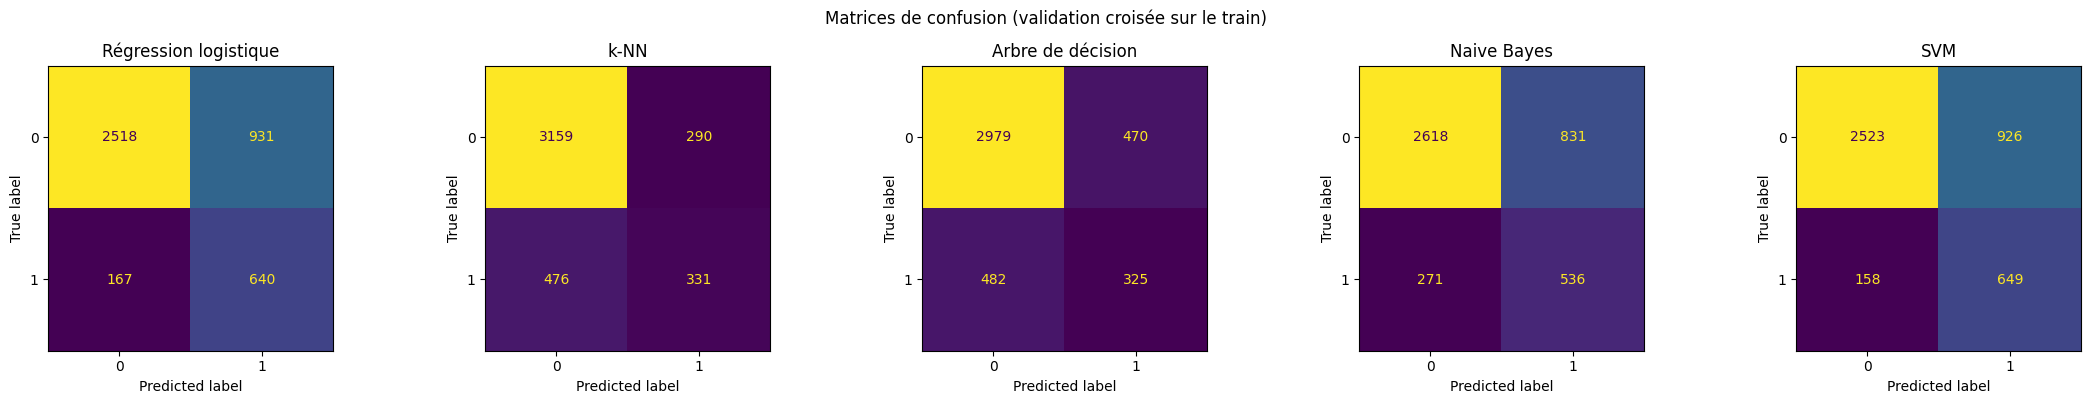

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Une matrice de confusion par modèle, côte à côte, à partir des prédictions de validation croisée (train)
# Lignes = vraie classe, colonnes = classe prédite
#   en haut à gauche : vrais négatifs (pas bon, prédit pas bon)   | en haut à droite : faux positifs (fausses alertes)
#   en bas à gauche : faux négatifs (bons vins ratés)             | en bas à droite : vrais positifs (bons vins trouvés)
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for i, nom in enumerate(modeles):
    ConfusionMatrixDisplay.from_predictions(y_train, preds_cv[nom], ax=ax[i], colorbar=False)
    ax[i].set_title(nom)
plt.suptitle("Matrices de confusion (validation croisée sur le train)")
plt.tight_layout()
plt.show()

La ligne du bas correspond aux 807 vrais bons vins du train. On voit deux comportements différents :
- la régression logistique et le SVM (avec `class_weight="balanced"`) trouvent environ 80 % des bons vins (640 et 649 sur 807), mais ils font beaucoup de fausses alertes (plus de 900 vins moyens prédits bons) ;
- le k-NN et l'arbre sont plus « prudents » : moins de fausses alertes (290 et 470), mais ils ratent environ 60 % des bons vins ;
- Naive Bayes est entre les deux (536 bons vins trouvés, 831 fausses alertes).

Selon l'utilisation, on pourrait préférer l'un ou l'autre (par exemple un caviste qui veut être sûr de ne recommander que de bons vins privilégierait la précision).

### Courbes ROC

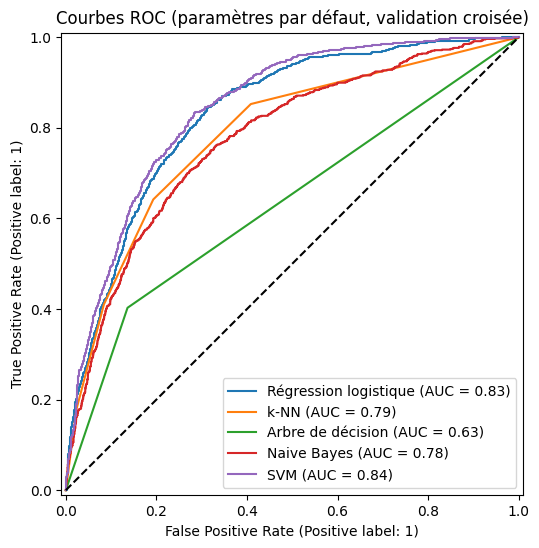

In [ ]:
from sklearn.metrics import RocCurveDisplay


# Plus la courbe monte vite vers le coin en haut à gauche, meilleur est le modèle
fig, ax = plt.subplots(figsize=(7, 6))
for nom in modeles:
    RocCurveDisplay.from_predictions(y_train, scores_cv[nom], name=nom, ax=ax)
plt.plot([0, 1], [0, 1], "k--")
plt.title("Courbes ROC (paramètres par défaut, validation croisée)")
plt.show()

Le SVM a la courbe la plus haute, la régression logistique est juste derrière. La courbe de l'arbre a une forme bizarre avec un seul « coude » :
c'est parce que l'arbre non limité donne quasiment que des probabilités 0 ou 1 (feuilles pures), ce qui confirme le sur-apprentissage.

### Biais / variance
On compare le F1 sur le train avec le F1 en validation croisée (5 folds).
Si le score train est beaucoup plus haut que le score de validation → **variance** (sur-apprentissage).
Si les deux sont bas et proches → **biais** (modèle trop simple).

In [ ]:
# Diagnostic biais / variance : on compare le F1 sur le train au F1 en validation croisée
biais_var = []
for nom, model in modeles.items():

    cv = cross_val_score(model, X_train_sc, y_train, cv=5, scoring="f1")
    biais_var.append({"modèle": nom,
                      "F1 train": resultats.loc[nom, "F1 train"],
                      "F1 validation (CV)": cv.mean(),
                      "écart-type CV": cv.std()})
biais_var = pd.DataFrame(biais_var).set_index("modèle").round(3)

biais_var["écart"] = biais_var["F1 train"] - biais_var["F1 validation (CV)"]
biais_var

,F1 train,F1 validation (CV),écart-type CV,écart
modèle,,,,
Régression logistique,0.537,0.539,0.026,-0.002
k-NN,0.645,0.464,0.007,0.181
Arbre de décision,1.000,0.405,0.024,0.595
Naive Bayes,0.496,0.493,0.013,0.003
SVM,0.577,0.545,0.017,0.032


On trace aussi la courbe **erreur en fonction de la complexité du modèle**, vue en cours (erreur d'entraînement et erreur de validation selon la complexité). On la trace pour les deux modèles dont la complexité se règle avec un seul paramètre :
- l'**arbre de décision** : plus il est profond (`max_depth`), plus il est complexe ;
- le **k-NN** : plus k est petit, plus il est complexe (avec k = 1, il colle à chaque point du train).

On utilise le F1 (plus il est haut, mieux c'est) : un écart qui grandit entre la courbe train et la courbe validation signale le sur-apprentissage.

Arbre - meilleure profondeur en validation : 3 -> F1 = 0.511
k-NN  - meilleur k en validation : 3 -> F1 = 0.472


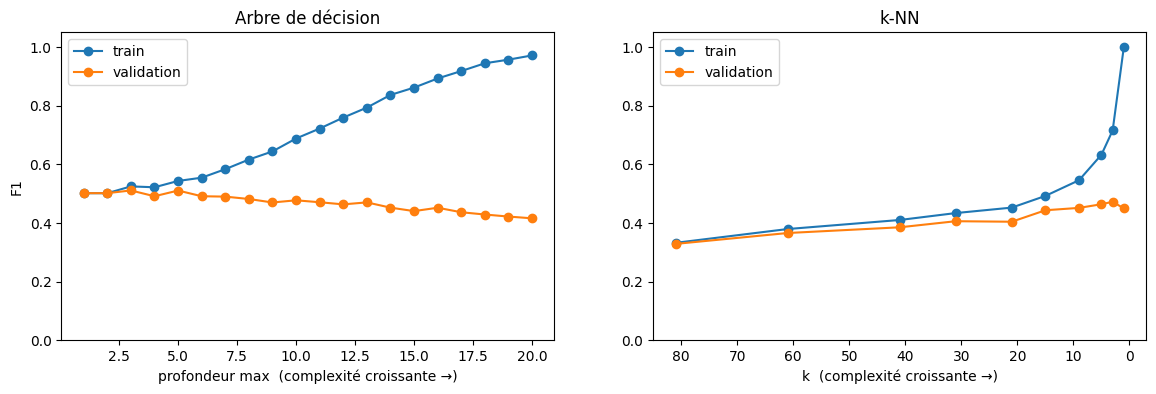

In [ ]:
from sklearn.model_selection import validation_curve

fig, ax = plt.subplots(1, 2, figsize=(14, 4))


profondeurs = list(range(1, 21))
sc_train, sc_val = validation_curve(DecisionTreeClassifier(criterion="entropy", class_weight="balanced", random_state=42),
                                    X_train_sc, y_train, param_name="max_depth", param_range=profondeurs,
                                    cv=5, scoring="f1")
ax[0].plot(profondeurs, sc_train.mean(axis=1), "o-", label="train")
ax[0].plot(profondeurs, sc_val.mean(axis=1), "o-", label="validation")
ax[0].set_title("Arbre de décision")
ax[0].set_xlabel("profondeur max  (complexité croissante →)")
ax[0].set_ylabel("F1")
ax[0].set_ylim(0, 1.05)
ax[0].legend()
print("Arbre - meilleure profondeur en validation :", profondeurs[sc_val.mean(axis=1).argmax()],
      "-> F1 =", round(sc_val.mean(axis=1).max(), 3))


ks = [1, 3, 5, 9, 15, 21, 31, 41, 61, 81]
sc_train, sc_val = validation_curve(KNeighborsClassifier(), X_train_sc, y_train,
                                    param_name="n_neighbors", param_range=ks, cv=5, scoring="f1")
ax[1].plot(ks, sc_train.mean(axis=1), "o-", label="train")
ax[1].plot(ks, sc_val.mean(axis=1), "o-", label="validation")
ax[1].invert_xaxis()
ax[1].set_title("k-NN")
ax[1].set_xlabel("k  (complexité croissante →)")
ax[1].set_ylim(0, 1.05)
ax[1].legend()
print("k-NN  - meilleur k en validation :", ks[sc_val.mean(axis=1).argmax()],
      "-> F1 =", round(sc_val.mean(axis=1).max(), 3))
plt.show()

- **Régression logistique** et **Naive Bayes** : le score train et le score de validation sont presque égaux (écart ≈ 0), mais assez bas → c'est plutôt un problème de **biais**. Le modèle est limité par sa forme (frontière linéaire pour la logistique, hypothèses trop fortes pour Naive Bayes).
- **Arbre de décision** : F1 de 1 sur le train mais 0.40 en validation → énorme **variance**. La courbe le montre bien : plus l'arbre est profond, plus le score train monte vers 1 alors que le score de validation baisse. Le meilleur compromis est atteint avec une profondeur de 3 (F1 = 0.51) : à gauche le modèle est trop simple (biais), à droite il apprend le bruit (variance). C'est exactement la courbe du cours.
- **k-NN** (k = 5 par défaut) : écart de 0.18, il sur-apprend aussi. La courbe montre que le F1 de validation baisse quand k augmente : sans `class_weight`, un grand k fait voter beaucoup de voisins, la classe majoritaire (« pas bon ») l'emporte presque toujours et le modèle trouve de moins en moins de bons vins. Le k-NN est donc coincé entre la variance (petit k) et le déséquilibre des classes (grand k).
- **SVM** : petit écart (0.03) et meilleur score de validation, c'est le modèle qui a le meilleur compromis biais/variance pour l'instant.

## 9. Optimisation des hyperparamètres

Comme demandé dans le sujet, on utilise `GridSearchCV` (teste toutes les combinaisons de la grille) pour les modèles qui ont peu de paramètres,
et `RandomizedSearchCV` (teste un nombre fixé de combinaisons tirées au hasard) pour le SVM et le k-NN, ce qui est plus rapide.
Chaque combinaison est évaluée par validation croisée à 5 folds sur le train, en maximisant le F1.

On ne règle que des hyperparamètres vus en cours :
- **régression logistique** : `C`, l'inverse de la force de la régularisation (Ridge / L2) ;
- **arbre** : sa complexité (`max_depth`, `min_samples_leaf`), avec le critère d'entropie ;
- **k-NN** : le nombre de voisins k et la distance (`p=1` : Manhattan, `p=2` : euclidienne) ;
- **SVM** : `C` (compromis marge / erreurs) et `gamma` (portée du noyau RBF).

**Naive Bayes gaussien** n'a pas d'hyperparamètre à régler : il estime seulement une moyenne et un écart-type par variable et par classe. On le garde tel quel.

> ###  Comprendre : les hyperparamètres
> - Un **paramètre** est appris automatiquement par le modèle (par exemple les poids de la régression logistique).
> - Un **hyperparamètre** est un réglage **choisi par nous avant** l'apprentissage (le nombre de voisins k, la profondeur max d'un arbre, C pour le SVM…). C'est comme les réglages d'un four : la température n'est pas « apprise » par le gâteau.
>
> **Comment trouver les meilleurs réglages ?**
> | Méthode | Principe | Avantage / inconvénient |
> |---|---|---|
> | **Grid Search** | teste **toutes** les combinaisons d'une grille | exhaustif mais lent si la grille est grande |
> | **Random Search** | tire **au hasard** un nombre fixé de combinaisons | plus rapide, et peut tomber sur des valeurs hors grille |
>
> Chaque combinaison est évaluée en **validation croisée sur le train**. Le test reste intact jusqu'à la toute fin.

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


# Régression logistique

grid_lr = GridSearchCV(LogisticRegression(max_iter=1000),
                       {"C": [0.001, 0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]},
                       cv=5, scoring="f1")
grid_lr.fit(X_train_sc, y_train)


print("Régression logistique :", grid_lr.best_params_, "-> F1 =", round(grid_lr.best_score_, 3))


grid_tree = GridSearchCV(DecisionTreeClassifier(criterion="entropy", random_state=42),
                         {"max_depth": [3, 5, 7, 10, 15, None], "min_samples_leaf": [1, 5, 10, 20, 50],
                          "class_weight": [None, "balanced"]},
                         cv=5, scoring="f1")
grid_tree.fit(X_train_sc, y_train)
print("Arbre de décision :", grid_tree.best_params_, "-> F1 =", round(grid_tree.best_score_, 3))

Régression logistique : {'C': 0.01, 'class_weight': 'balanced'} -> F1 = 0.54
Arbre de décision : {'class_weight': 'balanced', 'max_depth': 3, 'min_samples_leaf': 1} -> F1 = 0.511


In [ ]:
# k-NN : grid search puis random search pour comparer

grid_knn = GridSearchCV(KNeighborsClassifier(),
                        {"n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31], "p": [1, 2]},
                        cv=5, scoring="f1")
grid_knn.fit(X_train_sc, y_train)

# cv_results_['params'] = liste de toutes les combinaisons testées (9 x 2 = 18)
print("k-NN (grid)   :", grid_knn.best_params_, "-> F1 =", round(grid_knn.best_score_, 3),
      f"({len(grid_knn.cv_results_['params'])} combinaisons)")


rand_knn = RandomizedSearchCV(KNeighborsClassifier(),
                              {"n_neighbors": range(1, 40), "p": [1, 2]},
                              n_iter=10, cv=5, scoring="f1", random_state=42)
rand_knn.fit(X_train_sc, y_train)
print("k-NN (random) :", rand_knn.best_params_, "-> F1 =", round(rand_knn.best_score_, 3), "(10 combinaisons)")

# On garde la meilleure des deux recherches
best_knn = grid_knn if grid_knn.best_score_ >= rand_knn.best_score_ else rand_knn

k-NN (grid)   : {'n_neighbors': 1, 'p': 1} -> F1 = 0.482 (18 combinaisons)
k-NN (random) : {'p': 1, 'n_neighbors': 1} -> F1 = 0.482 (10 combinaisons)


In [ ]:
# SVM : random search sur C et gamma

rand_svm = RandomizedSearchCV(SVC(class_weight="balanced", random_state=42),
                              {"C": [0.1, 0.3, 1, 3, 10, 30, 100],
                               "gamma": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]},
                              n_iter=20, cv=5, scoring="f1", random_state=42)
rand_svm.fit(X_train_sc, y_train)
print("SVM (random) :", rand_svm.best_params_, "-> F1 =", round(rand_svm.best_score_, 3))

SVM (random) : {'gamma': 0.01, 'C': 100} -> F1 = 0.544


Ce qu'on peut retenir de l'optimisation :
- **arbre de décision** : c'est lui qui gagne le plus (F1 en CV de 0.40 à 0.51). La grid search a choisi `max_depth=3`, la même profondeur que la courbe de complexité : en limitant la profondeur, on l'empêche d'apprendre le bruit ;
- **régression logistique** : `C=0.01` (régularisation forte) avec `class_weight="balanced"`, mais le gain est quasi nul (0.539 → 0.540) : le modèle était déjà à son maximum, sa limite vient de sa frontière linéaire (biais) ;
- **k-NN** : la grid search et la random search trouvent le même réglage, k = 1 avec la distance de Manhattan (F1 = 0.482 contre 0.464 par défaut), alors que la random search n'a testé que 10 combinaisons au lieu de 18. Mais k = 1 est le cas le plus extrême de variance (chaque vin est classé comme son plus proche voisin). Le F1 préfère un petit k parce que, sans `class_weight`, c'est la seule façon pour le k-NN de prédire assez de bons vins ;
- **SVM** : C = 100 et gamma = 0.01, le F1 reste le même qu'avec les paramètres par défaut (0.544 contre 0.545) : les réglages par défaut du SVM étaient déjà bons ;
- **Naive Bayes** : pas d'hyperparamètre à régler.

Pour la régression logistique et l'arbre, la recherche a choisi `class_weight="balanced"`, ce qui montre bien qu'il faut prendre en compte le déséquilibre des classes.

### Évaluation finale sur le test

On choisit le meilleur modèle d'après le **F1 en validation croisée**, puis on évalue tous les modèles optimisés sur le test. C'est la seule fois où le test est utilisé.

In [ ]:
# best_estimator_ = le modèle déjà réglé avec les meilleurs paramètres trouvés
modeles_opt = {
    "Régression logistique": grid_lr.best_estimator_,
    "k-NN": best_knn.best_estimator_,
    "Arbre de décision": grid_tree.best_estimator_,
    "Naive Bayes": GaussianNB(),
    "SVM": rand_svm.best_estimator_,
}

# F1 en validation croisée des modèles optimisés (c'est sur CE score qu'on choisit le meilleur modèle)
f1_cv_opt = pd.Series({
    "Régression logistique": grid_lr.best_score_,
    "k-NN": best_knn.best_score_,
    "Arbre de décision": grid_tree.best_score_,
    "Naive Bayes": biais_var.loc["Naive Bayes", "F1 validation (CV)"],
    "SVM": rand_svm.best_score_,
}).round(3)

# ÉVALUATION FINALE sur le test : c'est la SEULE fois où on utilise le jeu de test
resultats_opt = evaluer_test(modeles_opt)

resultats_opt["F1 CV"] = f1_cv_opt
resultats_opt.sort_values("F1 CV", ascending=False)

,accuracy,précision,rappel,F1,AUC,F1 train,F1 CV
modèle,,,,,,,
SVM,0.736,0.403,0.817,0.540,0.850,0.573,0.544
Régression logistique,0.735,0.400,0.797,0.533,0.817,0.541,0.540
Arbre de décision,0.709,0.366,0.733,0.488,0.791,0.525,0.511
Naive Bayes,0.733,0.382,0.653,0.482,0.759,0.496,0.493
k-NN,0.822,0.532,0.540,0.536,0.714,1.000,0.482


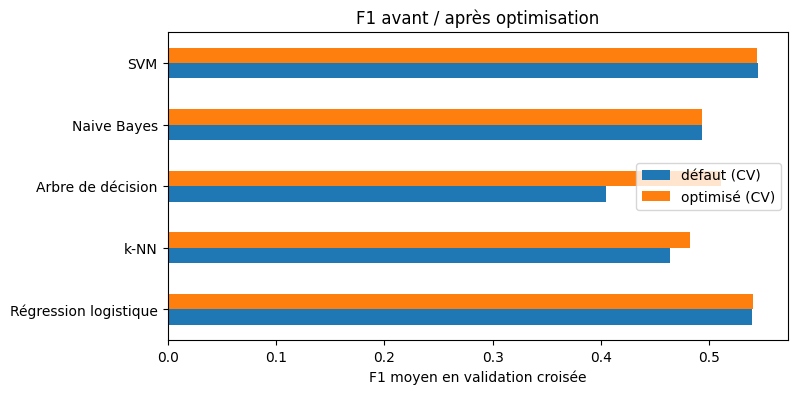

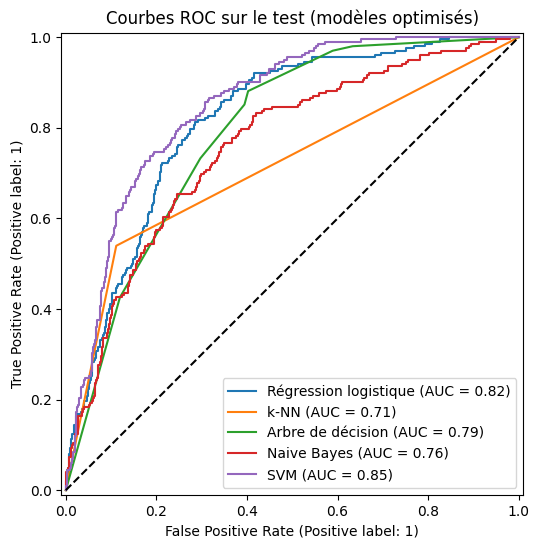

In [ ]:
# Graphique 1 : F1 en validation croisée avant et après optimisation, pour chaque modèle

comparaison = pd.DataFrame({"défaut (CV)": biais_var["F1 validation (CV)"], "optimisé (CV)": f1_cv_opt})
comparaison.plot.barh(figsize=(8, 4))   # barres horizontales, 2 barres par modèle
plt.xlabel("F1 moyen en validation croisée")
plt.title("F1 avant / après optimisation")
plt.show()

# Graphique 2 : courbes ROC des modèles optimisés sur le test (évaluation finale)
fig, ax = plt.subplots(figsize=(7, 6))
for nom, model in modeles_opt.items():
    RocCurveDisplay.from_predictions(y_test, score_proba(model, X_test_sc), name=nom, ax=ax)
plt.plot([0, 1], [0, 1], "k--")
plt.title("Courbes ROC sur le test (modèles optimisés)")
plt.show()

Sur le test, les scores sont proches de ceux obtenus en validation croisée pour le SVM (0.540 contre 0.544), la régression logistique (0.533 contre 0.540) et Naive Bayes (0.482 contre 0.493) : nos résultats sont cohérents.

Le **k-NN** fait mieux sur le test (0.536) qu'en validation croisée (0.482), mais il a la plus mauvaise AUC (0.71) et un F1 de 1 sur le train : avec k = 1 il colle complètement aux données d'entraînement. Ce bon score sur le test est donc en partie dû à la chance, et ce n'est pas sur le test qu'on choisit le modèle (sinon on utiliserait le test pour faire un choix, ce que le cours interdit).

Le **SVM** est le meilleur en validation croisée (F1 = 0.544) **et** sur le test (F1 = 0.540, AUC = 0.85), avec un faible écart entre train et validation. On le choisit donc comme modèle final.

              precision    recall  f1-score   support

     pas bon       0.94      0.72      0.81       862
         bon       0.40      0.82      0.54       202

    accuracy                           0.74      1064
   macro avg       0.67      0.77      0.68      1064
weighted avg       0.84      0.74      0.76      1064



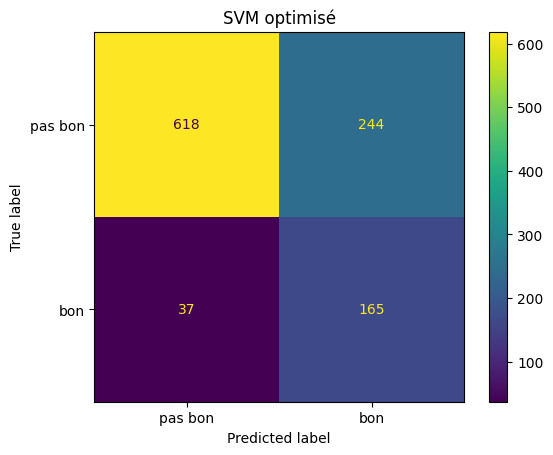

In [ ]:
from sklearn.metrics import classification_report

# Rapport détaillé du modèle final (SVM optimisé) sur le test
meilleur = modeles_opt["SVM"]
# classification_report donne précision, rappel et F1 pour CHAQUE classe

print(classification_report(y_test, meilleur.predict(X_test_sc), target_names=["pas bon", "bon"]))
ConfusionMatrixDisplay.from_estimator(meilleur, X_test_sc, y_test, display_labels=["pas bon", "bon"])
plt.title("SVM optimisé")
plt.show()

Pour finir, on regarde l'arbre de décision optimisé (seulement les premiers niveaux), qui est le modèle le plus facile à interpréter :

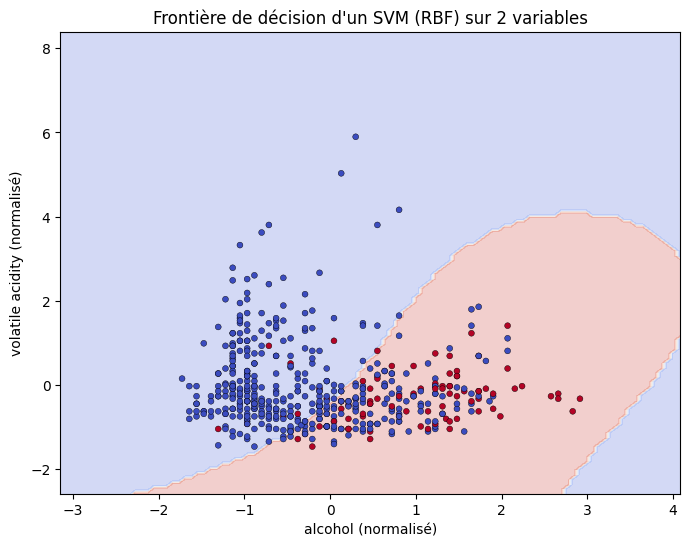

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

# On illustre avec les 2 variables les plus importantes (RFE) : alcohol et volatile acidity
vars2 = ["alcohol", "volatile acidity"]
idx2 = [list(X.columns).index(c) for c in vars2]
X2 = X_train_sc[:, idx2]   # train normalisé, seulement ces 2 colonnes

# Même type de SVM que le modèle final (mêmes C et gamma), mais appris sur 2 variables seulement
svm2 = SVC(kernel="rbf", C=rand_svm.best_params_["C"], gamma=rand_svm.best_params_["gamma"],
           class_weight="balanced").fit(X2, y_train)

fig, ax = plt.subplots(figsize=(8, 6))
# Zones colorées = ce que le SVM prédit en chaque point du plan (bleu = pas bon, rouge = bon)
DecisionBoundaryDisplay.from_estimator(svm2, X2, response_method="predict", cmap="coolwarm",
                                       alpha=0.25, ax=ax, xlabel=vars2[0] + " (normalisé)",
                                       ylabel=vars2[1] + " (normalisé)")
# Un échantillon de vins réels par-dessus (500 pour que ce soit lisible)
echantillon = np.random.RandomState(42).choice(len(X2), 500, replace=False)
ax.scatter(X2[echantillon, 0], X2[echantillon, 1], c=y_train.iloc[echantillon], cmap="coolwarm",
           edgecolor="k", linewidth=0.3, s=18)
ax.set_title("Frontière de décision d'un SVM (RBF) sur 2 variables")
plt.show()

Ce graphique illustre le principe du SVM (noyau RBF, mêmes réglages que le modèle final) sur les deux variables les plus importantes, `alcohol` et `volatile acidity`. Ce n'est pas le modèle final, qui utilise 12 variables.

- **Les bons vins (rouge) se trouvent à droite et en bas** : alcool élevé et acidité volatile faible à moyenne. Les vins à forte acidité volatile sont tous « pas bons ». Cela confirme la corrélation, la RFE et l'arbre.
- **La frontière est courbe et oblique** : plus l'acidité volatile augmente, plus il faut d'alcool pour qu'un vin soit classé « bon ». Un modèle linéaire ne pourrait pas tracer cette forme.
- **Les classes se chevauchent** : de nombreux vins « pas bons » tombent dans la zone rouge. Deux variables ne suffisent pas à bien séparer les classes, ce qui explique le F1 d'environ 0,54.
- **La zone rouge est large** à cause de `class_weight="balanced"` : le SVM classe « bon » au moindre doute pour ne pas rater de bons vins, d'où de nombreuses fausses alertes.




## 10. Conclusion

Dans ce projet on a essayé de prédire si un vin est bon (note ≥ 7) à partir de ses caractéristiques physico-chimiques.

Pour le prétraitement, on a fusionné les vins rouges et blancs, encodé le type en 0/1, supprimé les 1177 doublons, et gardé les valeurs aberrantes
car elles semblent réelles. Le dataset est déséquilibré (19 % de bons vins), donc on a utilisé un split stratifié, `class_weight="balanced"` et le F1 comme métrique principale.

L'analyse et la sélection de variables RFE montrent que **l'alcool** est de loin la variable la plus importante, suivie de l'acidité volatile.
On a quand même gardé toutes les variables car ça donnait les meilleurs résultats.

Les modèles ont été comparés et réglés uniquement en validation croisée sur le train, et le test n'a été utilisé qu'une fois, à la fin.
Parmi les 5 modèles, le **SVM avec noyau RBF** est le meilleur (F1 = 0.54, AUC = 0.85 sur le test) avec le meilleur compromis biais/variance.
La régression logistique est juste derrière mais limitée par sa frontière linéaire, l'arbre de décision sur-apprend s'il n'est pas limité, Naive Bayes est pénalisé par ses hypothèses,
et le k-NN souffre du déséquilibre des classes.

Les scores restent moyens (F1 autour de 0.5). On pense que c'est en partie lié aux données : la note vient de dégustateurs, donc elle est subjective,
et des vins notés 6 et 7 peuvent être très proches chimiquement. Pour aller plus loin, on pourrait essayer les méthodes d'ensemble vues en cours
(**Random Forest**, **AdaBoost** ou **Stacking**), choisir un autre seuil de décision que 0.5 à l'aide de la courbe ROC, ou faire des modèles séparés pour les rouges et les blancs.